# EIP Governance Velocity: a first analysis

**Author:** Misha Parekh · November 2026 · prepared for EIPsInsight (`docs/INTERN-TASKS.md`, item 2.3: Governance Velocity dashboard)

This notebook measures how fast Ethereum proposals move through their statuses, using only the public Git history of
[`ethereum/EIPs`](https://github.com/ethereum/EIPs) and [`ethereum/ERCs`](https://github.com/ethereum/ERCs). It covers the three things the roadmap asks for:

1. **Time in each status** (Draft, Review, Last Call, Stagnant), EIP vs ERC.
2. **Time to Final**, as survival curves, with proposals that are still open treated as censored.
3. **A stagnancy probability**: the chance that a Draft or Review proposal turns Stagnant in the next six months, given its age.

Everything is reproducible: `extract.py` rebuilds the two CSV files from fresh clones of both repositories.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
COL = {"EIP": "#3B6FB6", "ERC": "#D9822B"}

P = pd.read_csv("data/proposals.csv")        # one row per proposal file today
E = pd.read_csv("data/status_events.csv")    # one row per status change found in Git history
P["created"] = pd.to_datetime(P.created, errors="coerce")
E["date"] = pd.to_datetime(E.date, utc=True).dt.tz_convert(None)
DATA_DATE = E.date.max()
print(f"{len(P)} proposals ({(P.kind=='EIP').sum()} EIPs, {(P.kind=='ERC').sum()} ERCs); {len(E)} raw status events; data up to {DATA_DATE:%d %b %Y}")

1232 proposals (607 EIPs, 625 ERCs); 3315 raw status events; data up to 10 Nov 2026


## 1. Cleaning the status history

* The `Moved` status (ERCs moved to their own repository in October 2023) is dropped, because it is a file move, not a governance step.
* Old statuses are mapped to today's EIP-1 names: Abandoned → Withdrawn, Active → Living, Deferred → Stagnant. The few `Accepted`, `Superseded` and `Replaced` events (15 in total, pre-2021) are dropped.
* Repeated identical statuses are collapsed, and the same commit seen in both repositories is counted once.

In [2]:
E = E[E.number.isin(P.number) & (E.new != "Moved")].merge(P[["number", "kind", "created"]], on="number")
E["new"] = E.new.replace({"Abandoned": "Withdrawn", "Active": "Living", "Deferred": "Stagnant"})
E = E[E.new.isin(["Draft", "Review", "Last Call", "Final", "Stagnant", "Withdrawn", "Living"])].sort_values(["number", "date"])
E = E[E.groupby("number").new.shift() != E.new]
print(len(E), "clean status events")
P.groupby(["kind", "status"]).size().unstack(0).fillna(0).astype(int)

2907 clean status events


kind,EIP,ERC
status,,
Draft,152,230
Final,138,149
Last Call,30,14
Living,3,0
Review,13,62
Stagnant,235,161
Withdrawn,36,9


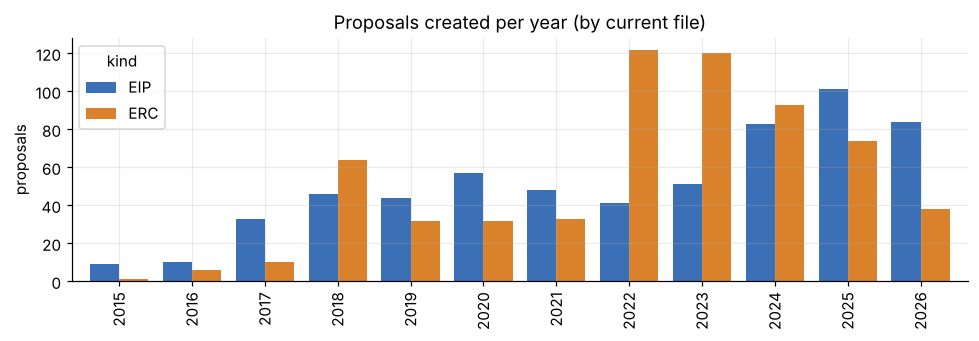

In [3]:
by_year = P.assign(year=P.created.dt.year).groupby(["year", "kind"]).size().unstack().fillna(0)
ax = by_year.loc[2015:].plot(kind="bar", color=[COL["EIP"], COL["ERC"]], figsize=(9, 3.2), width=.8)
ax.set_title("Proposals created per year (by current file)"); ax.set_xlabel(""); ax.set_ylabel("proposals"); plt.tight_layout()

## 2. Time spent in each status

Each status change opens a *spell* that ends at the next change. A spell with no later change is still open on the data date.
To keep the comparison fair, this section uses proposals created since 1 January 2020, after the current status process settled.

In [4]:
S = E.copy()
S["end"] = S.groupby("number").date.shift(-1)
S["open"] = S.end.isna(); S["end"] = S.end.fillna(DATA_DATE)
S["months"] = (S.end - S.date).dt.days / 30.44
S = S[S.number.isin(P[P.created >= "2020-01-01"].number)]
steps = ["Draft", "Review", "Last Call", "Stagnant"]
done = S[~S.open & S.new.isin(steps)]
tbl = done.groupby(["new", "kind"]).months.agg(["count", "median", lambda x: x.quantile(.25), lambda x: x.quantile(.75)])
tbl.columns = ["completed spells", "median months", "25th pct", "75th pct"]
still = S[S.new.isin(steps)].groupby(["new", "kind"]).open.mean().rename("share still open")
tbl.join(still).loc[steps].round(1)

completed spells  median months  25th pct  75th pct  \
new       kind                                                        
Draft     EIP                357            6.8       3.4      10.4   
          ERC                302            6.0       1.3       9.6   
Review    EIP                172            6.2       2.0       7.9   
          ERC                162            2.4       0.9       5.9   
Last Call EIP                 82            2.0       1.0       3.6   
          ERC                129            0.9       0.6       1.3   
Stagnant  EIP                 72            3.3       0.8      12.6   
          ERC                 37            3.0       0.3       8.8   

                share still open  
new       kind                    
Draft     EIP                0.3  
          ERC                0.4  
Review    EIP                0.1  
          ERC                0.3  
Last Call EIP                0.3  
          ERC                0.1  
Stagnant  EIP                0.7  
          ERC                0.7

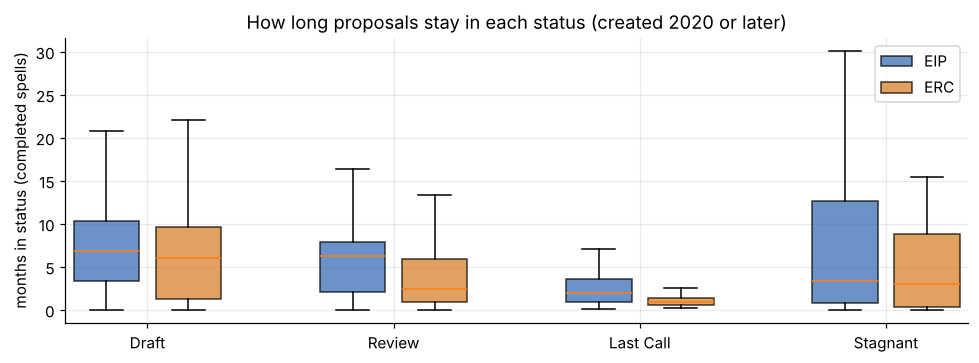

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.4))
data = [done[(done.new == s) & (done.kind == k)].months for s in steps for k in ["EIP", "ERC"]]
pos = [i * 3 + j for i in range(len(steps)) for j in (0, 1)]
b = ax.boxplot(data, positions=pos, widths=.8, patch_artist=True, showfliers=False)
for patch, k in zip(b["boxes"], ["EIP", "ERC"] * len(steps)): patch.set_facecolor(COL[k]); patch.set_alpha(.75)
ax.set_xticks([i * 3 + .5 for i in range(len(steps))]); ax.set_xticklabels(steps)
ax.set_ylabel("months in status (completed spells)"); ax.set_title("How long proposals stay in each status (created 2020 or later)")
ax.legend([b["boxes"][0], b["boxes"][1]], ["EIP", "ERC"]); plt.tight_layout()

## 3. Time to Final (survival analysis)

The clock starts at the proposal's `created` date. The event is the first move to **Final**. Proposals that are still open are
**censored** on the data date, and Withdrawn proposals are censored on the withdrawal date (a simple treatment of a competing outcome;
see the limitations). Living proposals are excluded. Kaplan-Meier curves then give the share of proposals that have reached Final after *t* months.

log-rank test, EIP vs ERC: p = 0.128


,proposals,reached Final,P(Final by 12 months),P(Final by 24 months),P(Final by 36 months)
kind,,,,,
EIP,463,78,0.099,0.167,0.231
ERC,511,120,0.165,0.230,0.253


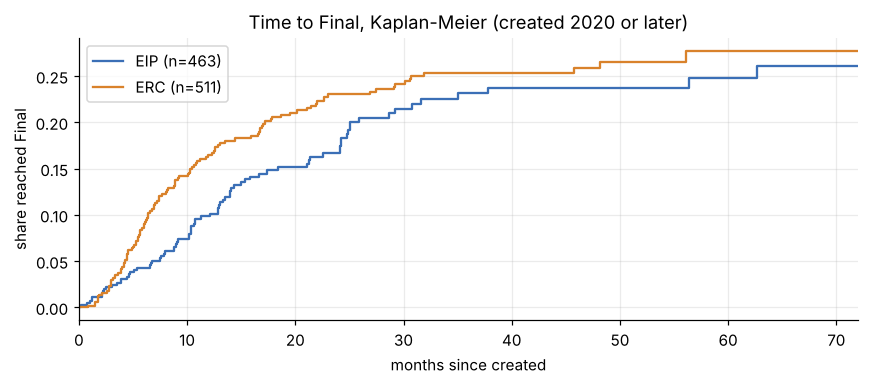

In [6]:
fin = E[E.new == "Final"].groupby("number").date.min()
wd = E[E.new == "Withdrawn"].groupby("number").date.min()
R = P[(P.created >= "2020-01-01") & (P.status != "Living")].copy()
R["final"], R["wd"] = R.number.map(fin), R.number.map(wd)
R["T"] = (R.final.fillna(R.wd).fillna(DATA_DATE) - R.created).dt.days / 30.44
R["F"] = R.final.notna(); R = R[R["T"] >= 0]
fig, ax = plt.subplots(figsize=(8, 3.6)); rows = []
for k in ["EIP", "ERC"]:
    d = R[R.kind == k]; km = KaplanMeierFitter(label=k).fit(d["T"], d.F)
    ax.step(km.timeline, 1 - km.survival_function_[k], where="post", color=COL[k], label=f"{k} (n={len(d)})")
    rows.append({"kind": k, "proposals": len(d), "reached Final": int(d.F.sum()),
                 **{f"P(Final by {m} months)": round(1 - float(km.predict(m)), 3) for m in (12, 24, 36)}})
ax.set_xlim(0, 72); ax.set_xlabel("months since created"); ax.set_ylabel("share reached Final"); ax.set_title("Time to Final, Kaplan-Meier (created 2020 or later)"); ax.legend(); plt.tight_layout()
lr = logrank_test(R[R.kind == "EIP"]["T"], R[R.kind == "ERC"]["T"], R[R.kind == "EIP"].F, R[R.kind == "ERC"].F)
print(f"log-rank test, EIP vs ERC: p = {lr.p_value:.3f}")
pd.DataFrame(rows).set_index("kind")

## 4. Stagnancy probability

Under EIP-1, a proposal in Draft, Review or Last Call that is inactive for six months or more can be marked **Stagnant**.
Here the clock again starts at `created`, the event is the first move to Stagnant, and proposals that reach Final or Withdrawn first are censored at that date.
This section uses proposals created since 1 January 2021, once the Stagnant status was in use.

The useful number for a dashboard is the **conditional** risk: for a proposal that is *a* months old and not yet Stagnant,
the chance it turns Stagnant within the next six months, `(S(a) − S(a+6)) / S(a)`.

EIP: P(Stagnant by 12 months) = 0.37, by 24 months = 0.61
ERC: P(Stagnant by 12 months) = 0.13, by 24 months = 0.27


,EIP,ERC
P(Stagnant within next 6 months),,
3 months old,0.24,0.07
6 months old,0.37,0.13
9 months old,0.29,0.14
12 months old,0.28,0.12
18 months old,0.12,0.04


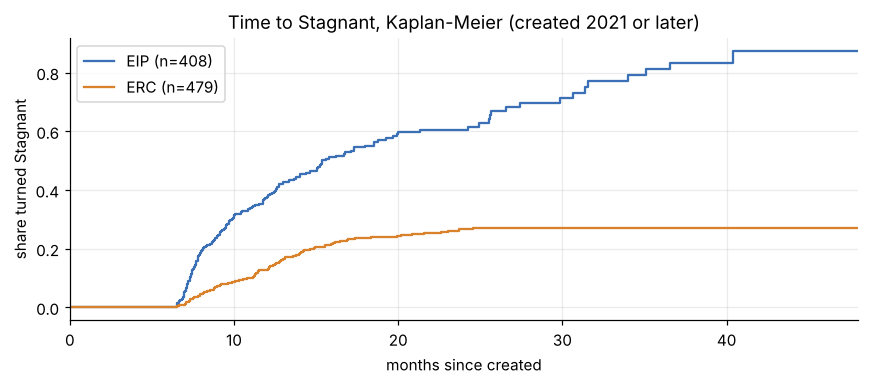

In [7]:
st = E[E.new == "Stagnant"].groupby("number").date.min()
Q = P[P.created >= "2021-01-01"].copy()
Q["st"] = Q.number.map(st)
Q["T"] = (Q.st.fillna(Q.number.map(fin)).fillna(Q.number.map(wd)).fillna(DATA_DATE) - Q.created).dt.days / 30.44
Q["Ev"] = Q.st.notna(); Q = Q[Q["T"] >= 0]
KM = {}; fig, ax = plt.subplots(figsize=(8, 3.6))
for k in ["EIP", "ERC"]:
    d = Q[Q.kind == k]; KM[k] = KaplanMeierFitter(label=k).fit(d["T"], d.Ev)
    ax.step(KM[k].timeline, 1 - KM[k].survival_function_[k], where="post", color=COL[k], label=f"{k} (n={len(d)})")
ax.set_xlim(0, 48); ax.set_xlabel("months since created"); ax.set_ylabel("share turned Stagnant"); ax.set_title("Time to Stagnant, Kaplan-Meier (created 2021 or later)"); ax.legend(); plt.tight_layout()

for k in KM: print(f"{k}: P(Stagnant by 12 months) = {1-float(KM[k].predict(12)):.2f}, by 24 months = {1-float(KM[k].predict(24)):.2f}")

def risk6(k, a):
    s0, s1 = float(KM[k].predict(a)), float(KM[k].predict(a + 6)); return (s0 - s1) / s0
pd.DataFrame({k: {f"{a} months old": round(risk6(k, a), 2) for a in (3, 6, 9, 12, 18)} for k in KM}).rename_axis("P(Stagnant within next 6 months)")

### A data gap: no ERC has been marked Stagnant since October 2023

The ERC curve above flattens out. Counting Stagnant moves by year shows why: in the ERCs repository's Git history, the last move to Stagnant is an
auto-stagnate bot commit on 15 October 2023 (UTC), just before ERCs moved to their own repository. There have been none since, although the ERCs repository
contains an `auto-stagnate-bot.yml` workflow. So the ERC numbers in this section describe 2021–2023 only, and the ERC column above is biased low.
For the per-proposal score below I use the EIP model, and for ERCs I only count how many Drafts are older than six months.

In [8]:
Sx = E[E.new == "Stagnant"].assign(year=lambda d: d.date.dt.year).groupby(["year", "kind"]).size().unstack().fillna(0).astype(int)
print("Last ERC move to Stagnant:", E[(E.new == "Stagnant") & (E.kind == "ERC")].date.max().date())
old_erc = P[(P.kind == "ERC") & (P.status == "Draft") & (P.created < DATA_DATE - pd.Timedelta(days=183))]
print(f"ERC Drafts created more than six months ago: {len(old_erc)} (activity not checked; Stagnant depends on inactivity, not age)")
Sx

Last ERC move to Stagnant: 2023-10-15
ERC Drafts created more than six months ago: 216 (activity not checked; Stagnant depends on inactivity, not age)


kind,EIP,ERC
year,,
2018,2,0
2019,1,0
2021,123,97
2022,29,34
2023,32,83
2024,45,0
2025,76,0
2026,18,0


### Applying it to proposals open today

Each open Draft or Review **EIP** gets the conditional six-month risk for its age (ERCs are left out because of the gap above). This is the per-proposal "stagnancy probability"
the Velocity page could show. It is age-based only; section 6 lists the obvious improvements.

In [9]:
open_now = P[P.status.isin(["Draft", "Review"]) & (P.created >= "2021-01-01") & (P.kind == "EIP")].copy()
open_now["age_months"] = ((DATA_DATE - open_now.created).dt.days / 30.44).round(1)
open_now["P_stagnant_6m"] = [round(risk6(k, a), 2) for k, a in zip(open_now.kind, open_now.age_months)]
print(f"{len(open_now)} open EIPs scored; median six-month stagnancy risk {open_now.P_stagnant_6m.median():.2f}")
open_now.sort_values("P_stagnant_6m", ascending=False)[["number", "kind", "status", "title", "age_months", "P_stagnant_6m"]].head(10)

164 open EIPs scored; median six-month stagnancy risk 0.27


,number,kind,status,title,age_months,P_stagnant_6m
1157,8250,EIP,Draft,Keyed Nonces for Frame Transactions,6.8,0.40
1156,8247,EIP,Draft,Ancestor-Indexed BALs,6.3,0.39
1154,8243,EIP,Draft,Batching Attestations at Source,6.3,0.39
1158,8252,EIP,Draft,Execution-Layer Reorg State Retention Window,6.6,0.39
1175,8289,EIP,Draft,Multi-block Access List Warming,6.3,0.39
1150,8219,EIP,Draft,Checked Arithmetic Opcodes,7.1,0.39
1153,8237,EIP,Draft,Independent CL/EL Sync,6.6,0.39
1151,8222,EIP,Draft,Lean Staking,7.1,0.39
831,7709,EIP,Draft,Read BLOCKHASH from Storage and Update Cost,29.8,0.38
1162,8256,EIP,Draft,Blob Streaming,6.2,0.38


## 5. Coming back from Stagnant

In [10]:
stag_spells = S[S.new == "Stagnant"]
revived = stag_spells[~stag_spells.open]
nxt = S.assign(nxt=S.groupby("number").new.shift(-1))
nxt = nxt[(nxt.new == "Stagnant") & nxt.nxt.notna()].nxt.value_counts()
print(f"{len(stag_spells)} Stagnant spells since 2020; {len(revived)} ended ({len(revived)/len(stag_spells):.0%}), median {revived.months.median():.1f} months later")
nxt.rename("next status after Stagnant").to_frame()

366 Stagnant spells since 2020; 109 ended (30%), median 3.2 months later


,next status after Stagnant
nxt,
Draft,61
Review,37
Withdrawn,9
Last Call,2


## 6. Limitations

* **Status history only.** The data records status changes, not every edit, comment or PR review. The Stagnant rule depends on *inactivity*, so a model that also used last-activity dates (commits, PR comments) from the EIPsInsight database would predict stagnancy far better than age alone.
* **Competing outcomes.** Withdrawn is treated as censoring in the time-to-Final curves. A competing-risks model (Aalen-Johansen) would separate "reached Final" from "withdrawn" properly.
* **Dates.** `created` comes from each file's front matter; status dates are commit dates, which can lag the decision by days.
* **ERC stagnation.** No ERC has moved to Stagnant since 15 October 2023 in the Git history, so ERC stagnancy after that date cannot be measured from statuses alone.
* **Process changes.** Status names and rules changed over time (Stagnant arrived in 2021, ERCs moved repositories in 2023), so the main analyses use 2020+ or 2021+ proposals only.

## 7. From notebook to `/analytics/velocity`

A first version of the page could show, on the existing stack (Next.js, oRPC, Prisma, Recharts):
1. **Median months in each status**, EIP vs ERC, with a date-range filter (section 2).
2. **Time-to-Final curves** by kind and by category (section 3).
3. **A stagnancy-risk badge** on each open proposal, recomputed nightly (section 4), first age-based, then with last-activity features.

I'd like to agree the first version with you before building it.